In [ ]:
#| default_exp audio

# Mel spectrograms and codec tokens

> The log mel spectrogram shared by every model here, and a look at codec tokens.

In the last notebook we loaded LJSpeech and found that a ten second clip is about 220,000 numbers. That's the problem with
audio: it's *big*, and nearly all of those numbers are boring. A waveform sample tells you the air pressure at one instant,
which is not something anyone has an opinion about. What we care about, and what a text-to-speech model needs to predict,
is the stuff that changes slowly: which sounds are being made, at what pitch, how loud.

So every TTS system starts by turning the waveform into something more compact and more meaningful. There are two
representations that matter today:

1. **The mel spectrogram**: a picture of which frequencies are present over time, with the frequency axis warped to match
   how ears work. This is what most TTS models from Tacotron to Kokoro predict.
2. **Codec tokens**: integers from a learned codebook, produced by a small neural network called a neural audio codec.
   This is what LLM-style TTS models (Orpheus, Pocket TTS) predict.

We'll build the first one from scratch in numpy, check our version against a reference implementation, and see what
it throws away. Then we'll use two pretrained codecs to see what tokens look like and how much you can squash speech
before it stops sounding like speech.

In [ ]:
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch
from IPython.display import Audio, display

In [ ]:
wav_dir = Path("../data/LJSpeech-1.1/wavs")
audio, sr = sf.read(wav_dir / "LJ001-0001.wav", dtype="float32")

print(f"{len(audio):,} samples at {sr} Hz = {len(audio) / sr:.2f} seconds")
Audio(audio, rate=sr)

212,893 samples at 22050 Hz = 9.66 seconds


## Step 1: chop the waveform into frames

Speech changes fast, but not *that* fast. Over a window of a few tens of milliseconds a vowel is pretty much the same
vowel. So the first thing we do is chop the signal into short overlapping frames, and we'll analyse each frame on its own.

Two numbers define the chopping:

- `n_fft`, the frame length. We'll use 1024 samples, which at 22,050 Hz is 46 ms.
- `hop`, how far we slide between frames. We'll use 256 samples, or 11.6 ms. So frames overlap by 75%.

These are the numbers Piper, HiFi-GAN and most other TTS repos use for 22 kHz audio, and once you pick them you're
stuck with them: the model that predicts spectrograms and the vocoder that turns them back into sound must agree.

In [ ]:
n_fft = 1024
hop = 256


def frame(signal, n_fft, hop):
    "Slice `signal` into overlapping frames of length `n_fft`, `hop` samples apart."
    return np.lib.stride_tricks.sliding_window_view(signal, n_fft)[::hop]


frames = frame(audio, n_fft, hop)
print(frames.shape, f"-> {frames.shape[0]} frames, one every {hop / sr * 1000:.1f} ms")

(828, 1024) -> 828 frames, one every 11.6 ms


## Step 2: window each frame

If we just cut a chunk out of a signal, the edges are abrupt: the signal is implicitly zero outside the frame, so there's
a sudden jump at each end. The Fourier transform sees that jump as a burst of energy at *every* frequency, which smears
our spectrum. The fix is to fade each frame in and out by multiplying by a bell-shaped window. The standard one is the
Hann window.

One gotcha: `np.hanning(n)` gives you a *symmetric* window (first and last samples both zero). The signal processing
convention, and what librosa and torch use, is the *periodic* version, which is what you'd get from `np.hanning(n + 1)[:-1]`.
The difference is tiny, but it will bite you when you compare against a reference. So let's write our own.

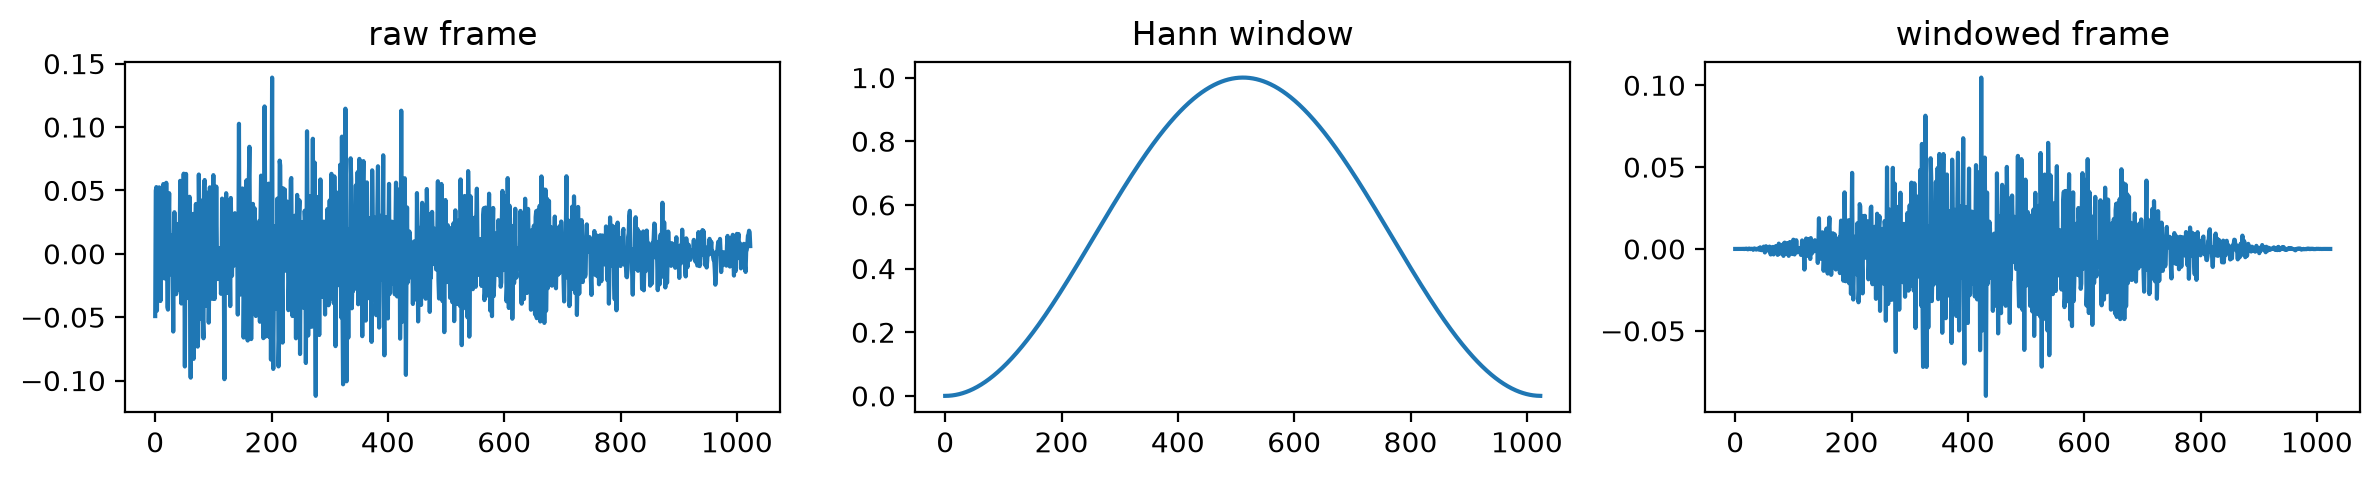

In [ ]:
window = 0.5 - 0.5 * np.cos(2 * np.pi * np.arange(n_fft) / n_fft)  # periodic Hann

i = 200  # A frame somewhere in the middle of a vowel
fig, axes = plt.subplots(1, 3, figsize=(12, 2.5))
axes[0].plot(frames[i])
axes[0].set_title("raw frame")
axes[1].plot(window)
axes[1].set_title("Hann window")
axes[2].plot(frames[i] * window)
axes[2].set_title("windowed frame")
plt.tight_layout()
plt.show()

## Step 3: FFT every frame

Now we take the Fourier transform of each windowed frame, exactly as we did with a single vowel in the first notebook.
`rfft` of 1024 real samples gives 513 complex numbers, one per frequency bin from 0 Hz to 11,025 Hz (half the sample
rate, the highest frequency the recording can contain). We keep the magnitude and throw away the phase. Hold that thought.

The result is a matrix of frames × frequency bins: a **spectrogram**.

In [ ]:
spectrum = np.abs(np.fft.rfft(frames * window, axis=1))  # (frames, 513)
freqs = np.fft.rfftfreq(n_fft, d=1 / sr)

print(spectrum.shape)
print(f"bin spacing: {freqs[1]:.1f} Hz")

(828, 513)
bin spacing: 21.5 Hz


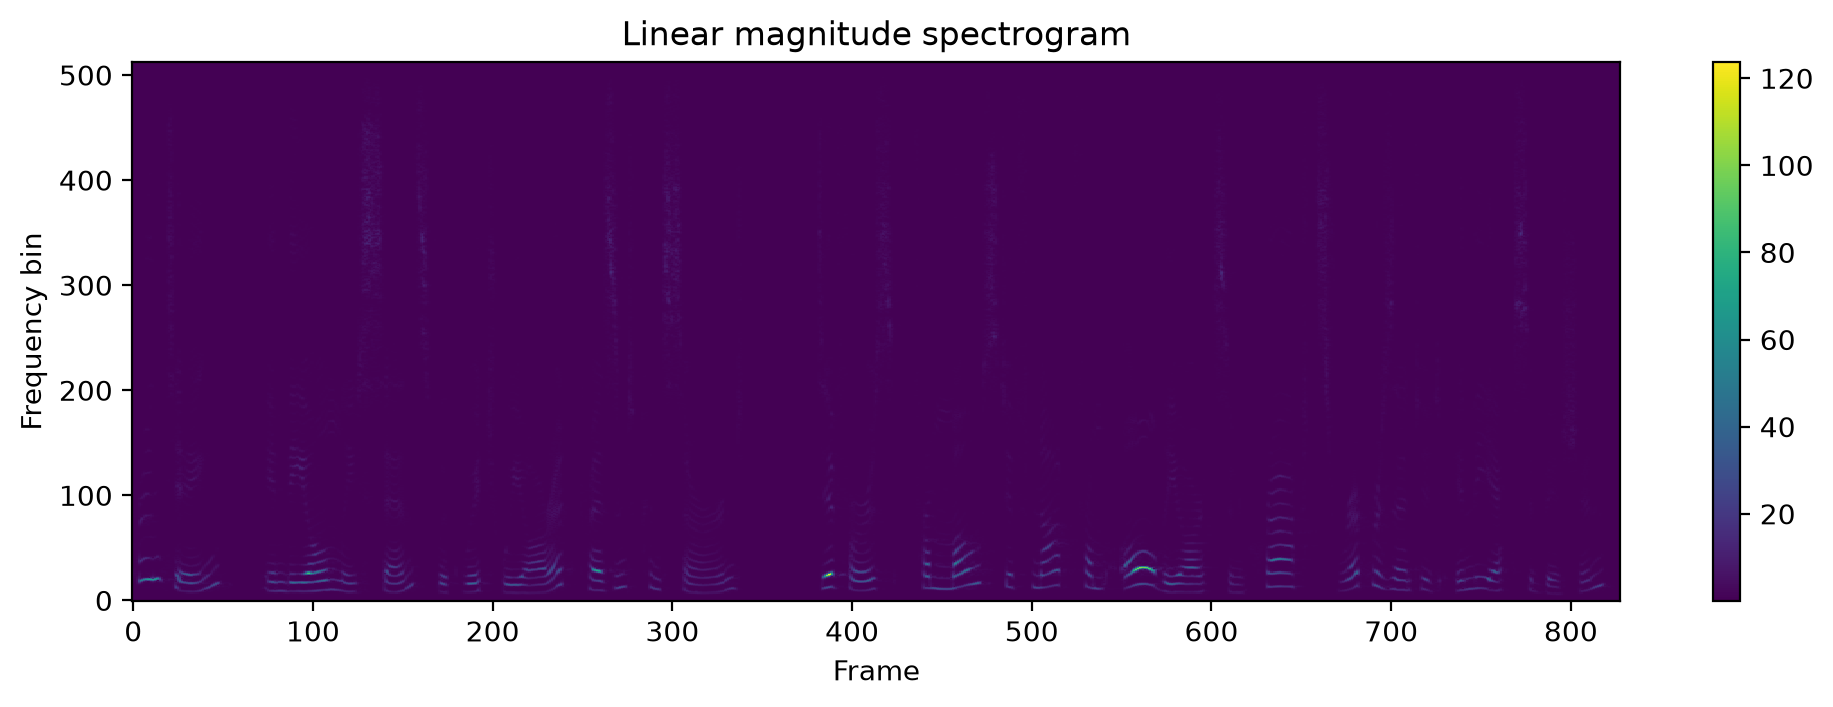

In [ ]:
def show(matrix, title="", ylabel="Frequency bin"):
    "Plot a (frames, features) matrix with time along the x axis."
    plt.figure(figsize=(12, 3.5))
    plt.imshow(matrix.T, origin="lower", aspect="auto", interpolation="nearest")
    plt.xlabel("Frame")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.colorbar()
    plt.show()


show(spectrum, "Linear magnitude spectrogram")

That's nearly all black, with a thin strip of activity at the bottom. Is the recording broken? No: it's that the loudest
components of speech (the low harmonics of the voice) are *thousands* of times bigger than the quiet ones (the hiss of an
"s"), and a linear colour scale can't show both.

Ears have the same problem and solve it the same way we're about to: they respond to loudness roughly logarithmically.
Doubling the energy sounds like one fixed step louder, not twice as loud. So we take the log.

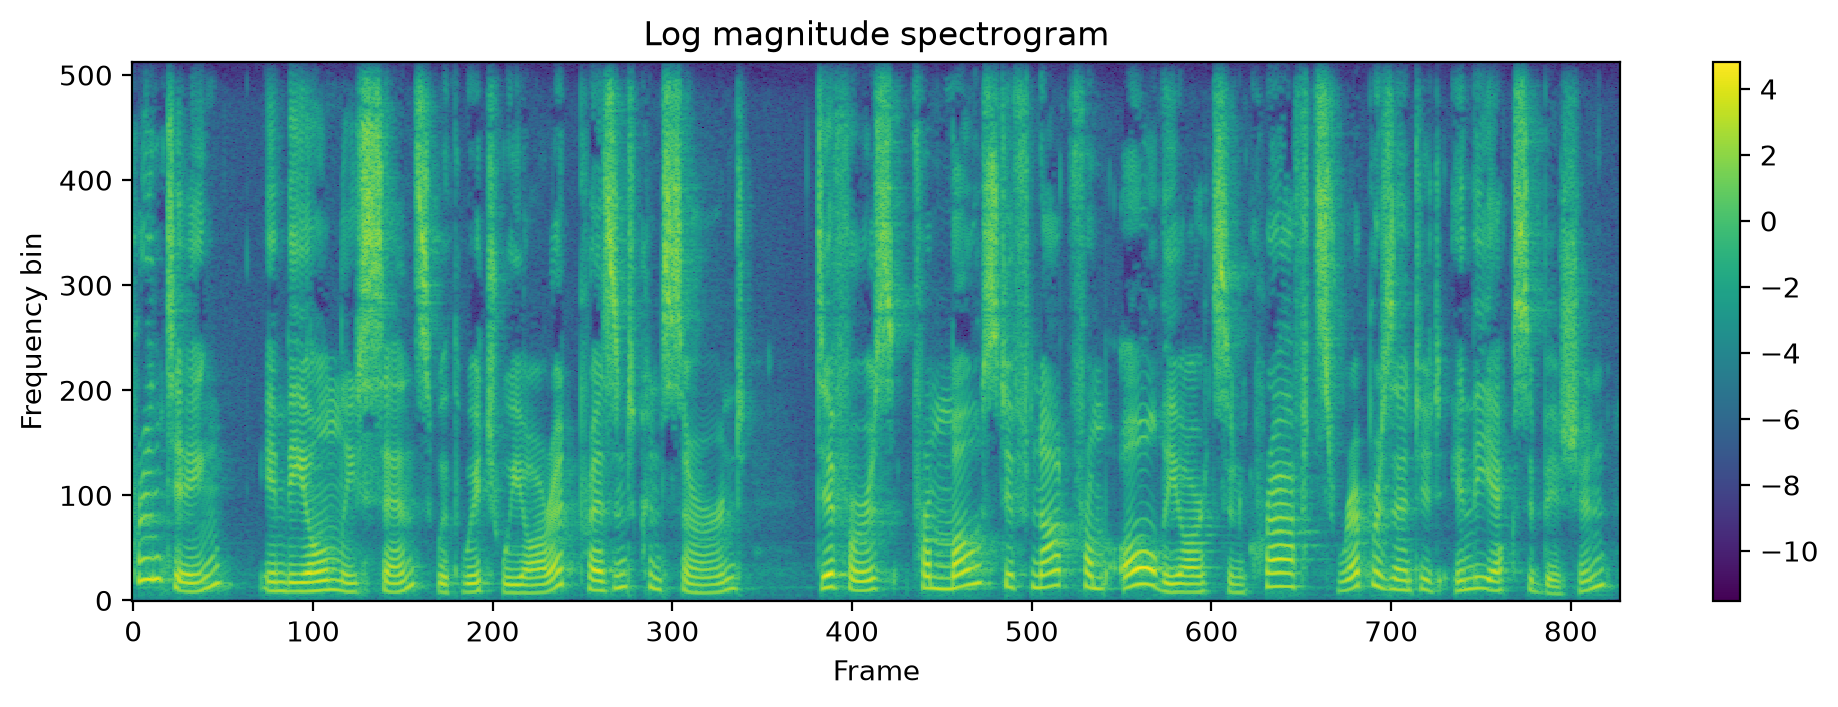

In [ ]:
log_spectrum = np.log(np.maximum(spectrum, 1e-5))  # Clamp so log(0) doesn't blow up
show(log_spectrum, "Log magnitude spectrogram")

Now we can see it. The horizontal stripes at the bottom are the harmonics of the voice, spaced at multiples of the pitch.
The bright blobs at higher frequencies are consonants. The vertical gaps are pauses between words.

Before going further, let's check we haven't made a mistake. librosa's `stft` does exactly what we just did, and the
whole point of writing it ourselves is to understand it, not to get a different answer.

In [ ]:
reference = np.abs(librosa.stft(audio, n_fft=n_fft, hop_length=hop, window="hann", center=False)).T
print(reference.shape, np.allclose(spectrum, reference, atol=1e-4))

(828, 513) True


## Step 4: the mel scale

We now have 513 frequency bins, evenly spaced 21.5 Hz apart. But ears don't treat frequencies evenly. The difference
between 100 Hz and 200 Hz is an octave, a huge musical distance. The difference between 10,000 Hz and 10,100 Hz is
imperceptible. Pitch perception is roughly logarithmic in frequency, just like loudness is logarithmic in energy.

The **mel scale** is a curve fitted to listening experiments in the 1930s that says how "far apart" two frequencies
sound. There are a couple of slightly different formulas in use; here's the common one:

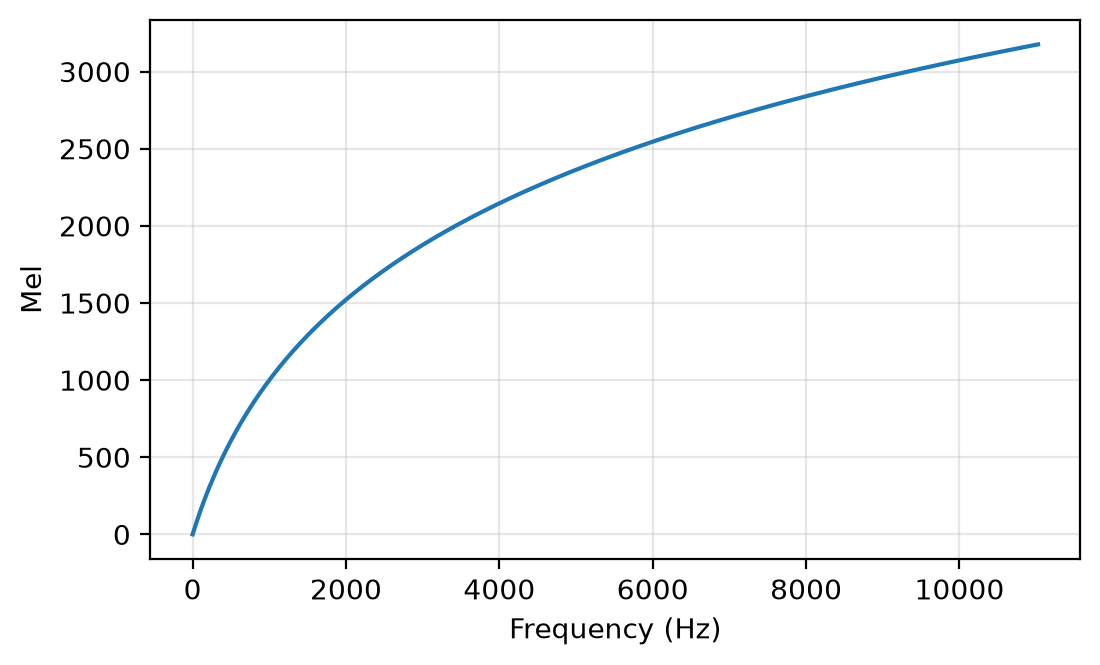

In [ ]:
def hz_to_mel(hz):
    return 2595 * np.log10(1 + hz / 700)


def mel_to_hz(mel):
    return 700 * (10 ** (mel / 2595) - 1)


hz = np.linspace(0, sr / 2, 500)
plt.figure(figsize=(6, 3.5))
plt.plot(hz, hz_to_mel(hz))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Mel")
plt.grid(alpha=0.3)
plt.show()

Roughly linear up to about 1,000 Hz, then logarithmic. Now the trick: we want to replace our 513 evenly spaced (in Hz)
bins with a smaller number of bins that are evenly spaced *in mel*. Eighty is the conventional number.

We do this with a **filterbank**: a matrix with one row per mel bin, where each row is a triangle that picks out a range
of the original frequency bins and averages them. Low mel bins are narrow triangles covering a few Hz bins. High mel bins
are wide triangles covering dozens. Let's build it.

(80, 513)


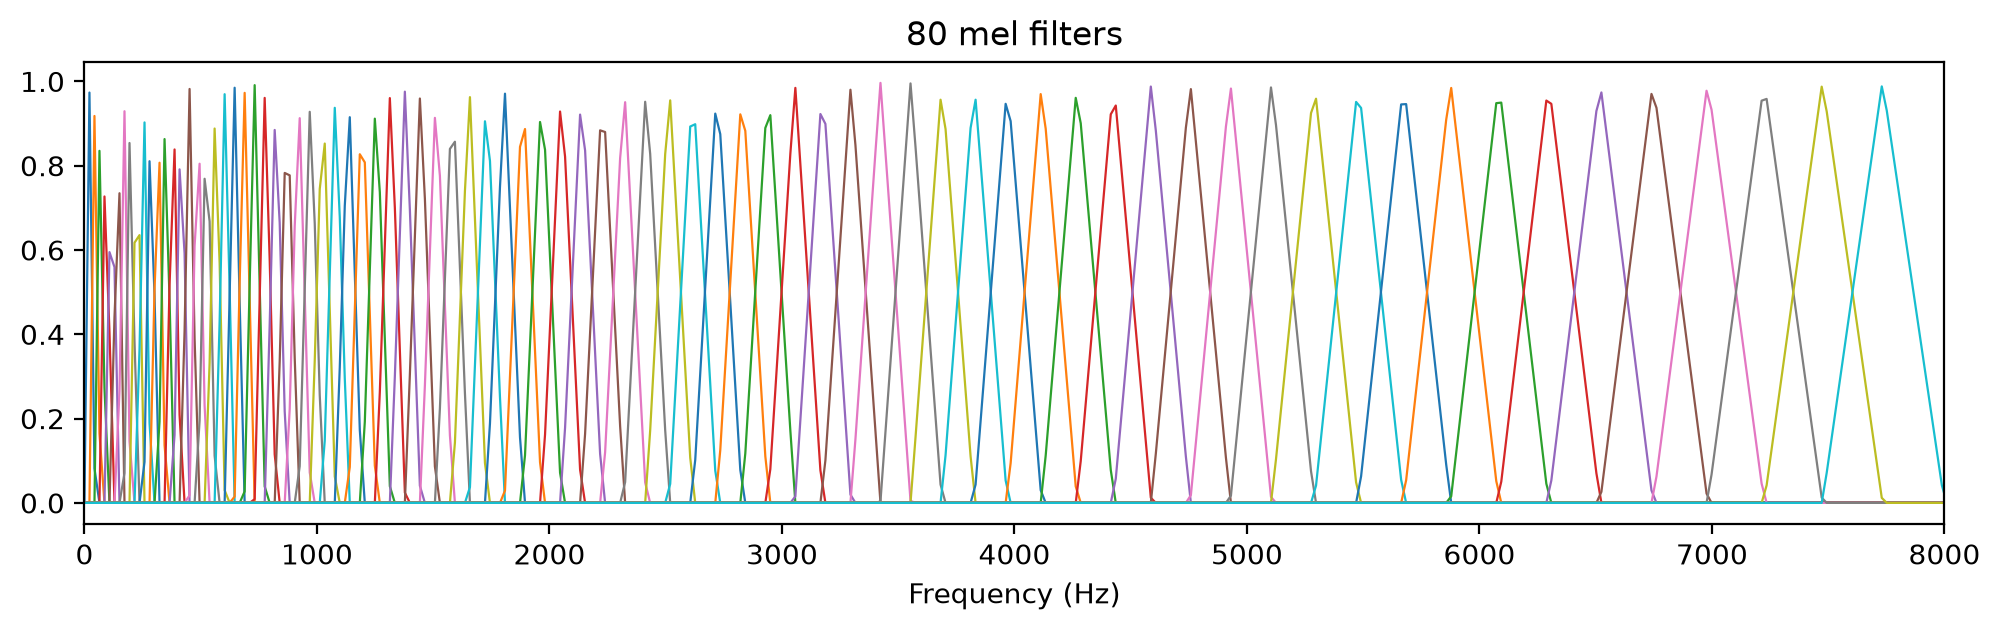

In [ ]:
n_mels = 80
f_min, f_max = 0, 8000  # Piper/VITS convention: ignore everything above 8 kHz


def mel_filterbank(sr, n_fft, n_mels, f_min, f_max):
    "Return a (n_mels, n_fft // 2 + 1) matrix of triangular filters evenly spaced on the mel scale."
    freqs = np.fft.rfftfreq(n_fft, d=1 / sr)
    # n_mels triangles need n_mels + 2 edge points: each triangle spans three consecutive points.
    mel_points = np.linspace(hz_to_mel(f_min), hz_to_mel(f_max), n_mels + 2)
    hz_points = mel_to_hz(mel_points)

    filterbank = np.zeros((n_mels, len(freqs)))
    for i in range(n_mels):
        lo, mid, hi = hz_points[i : i + 3]
        rising = (freqs - lo) / (mid - lo)
        falling = (hi - freqs) / (hi - mid)
        filterbank[i] = np.maximum(0, np.minimum(rising, falling))
    return filterbank


filterbank = mel_filterbank(sr, n_fft, n_mels, f_min, f_max)
print(filterbank.shape)

plt.figure(figsize=(12, 3))
for row in filterbank:
    plt.plot(freqs, row, lw=0.8)
plt.xlim(0, 8000)
plt.xlabel("Frequency (Hz)")
plt.title("80 mel filters")
plt.show()

Applying the filterbank is one matrix multiply: each frame's 513 power values become 80 mel values. (We use *power*,
the square of magnitude, because that's what adds up sensibly when you average bins. Some repos use magnitude instead.
It doesn't matter as long as everyone in your pipeline agrees.) Then log, as before.

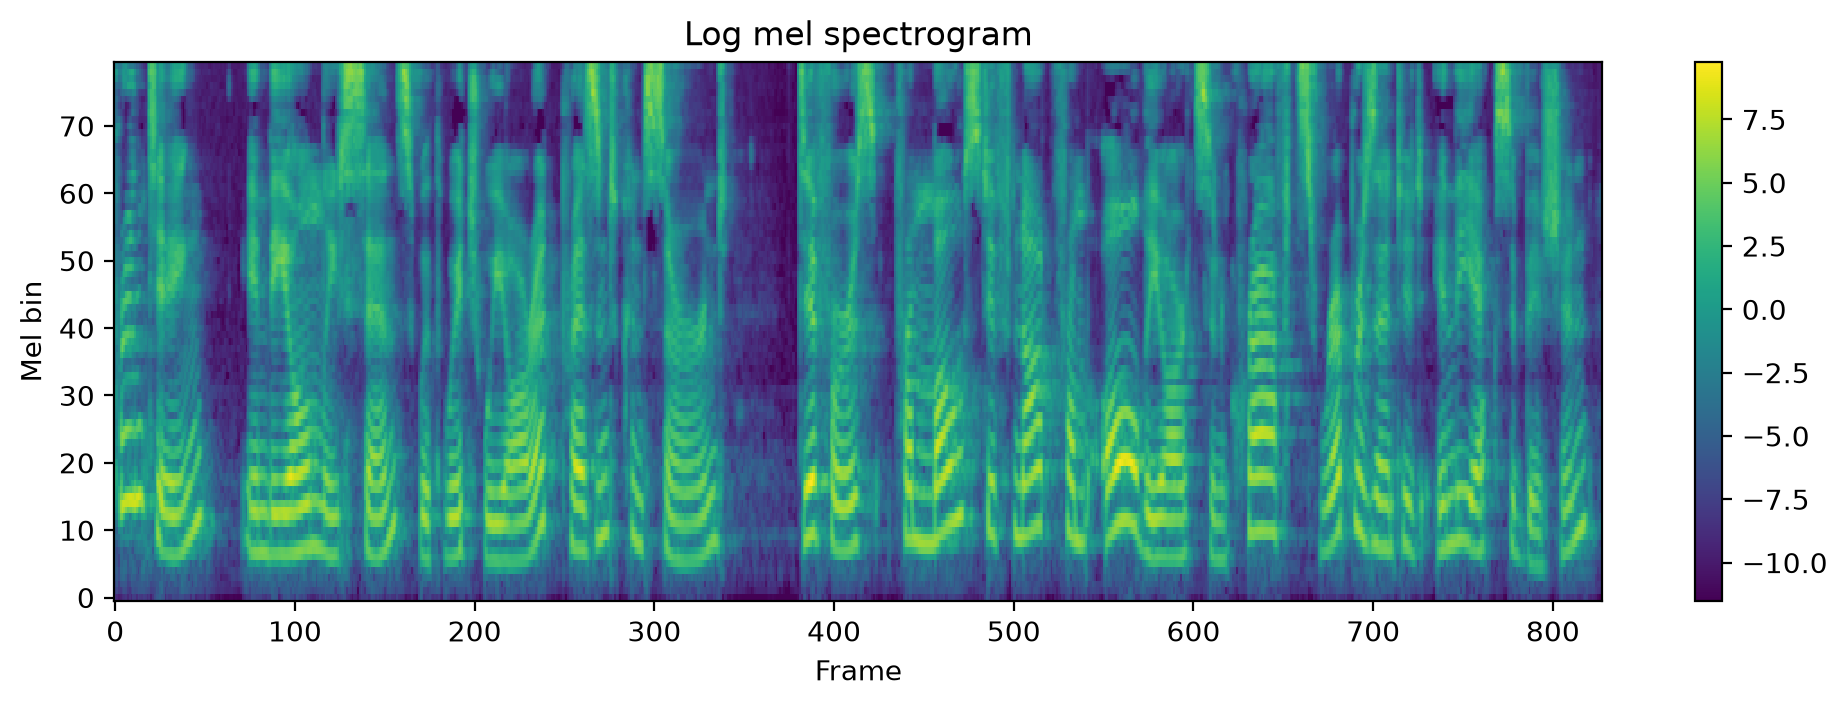

In [ ]:
mel_power = (spectrum**2) @ filterbank.T  # (frames, 80)
log_mel = np.log(np.maximum(mel_power, 1e-5))

show(log_mel, "Log mel spectrogram", ylabel="Mel bin")

Compare this with the log spectrogram above. Same clip, same frames, but the bottom of the picture, where the voice
harmonics live, has been stretched out and the top squashed. The pitch contour of each word is now clearly visible as
the curve of the lowest stripes. That's the information a TTS model most needs to get right, so it's good to spend most
of our 80 numbers on it.

Check against librosa again. We tell it to use the same mel formula as ours (`htk=True`) and not to normalise the
filter areas (`norm=None`), because that's what we built. Its defaults are slightly different and both are common in
the wild, which is exactly why you should never mix a spectrogram from one library with a vocoder trained on another.

In [ ]:
ref_fb = librosa.filters.mel(sr=sr, n_fft=n_fft, n_mels=n_mels, fmin=f_min, fmax=f_max, htk=True, norm=None)
print("filterbank matches:", np.allclose(filterbank, ref_fb, atol=1e-6))

ref_mel = librosa.feature.melspectrogram(
    S=reference.T**2, sr=sr, n_fft=n_fft, n_mels=n_mels, fmin=f_min, fmax=f_max, htk=True, norm=None
).T
print("mel spectrogram matches:", np.allclose(mel_power, ref_mel, atol=1e-3))

filterbank matches: True
mel spectrogram matches: True


So what did we gain? Let's count.

In [ ]:
print(f"waveform:        {audio.size:>9,} numbers")
print(f"spectrogram:     {spectrum.size:>9,} numbers  ({spectrum.shape[0]} frames x {spectrum.shape[1]} bins)")
print(f"mel spectrogram: {log_mel.size:>9,} numbers  ({log_mel.shape[0]} frames x {log_mel.shape[1]} mels)")

waveform:          212,893 numbers
spectrogram:       424,764 numbers  (828 frames x 513 bins)
mel spectrogram:    66,240 numbers  (828 frames x 80 mels)


Notice the plain spectrogram is *twice as many* numbers as the waveform. That's the 75% overlap between frames: every
sample is counted four times. The mel step is what actually shrinks things, to about a third of the waveform.

Three times fewer numbers is nice but it isn't the point. The point is that the 80 numbers in a mel frame are
*smooth, slowly-varying, perceptually meaningful* quantities. Adjacent frames look alike. A model predicting them can
be wrong by a little and still sound fine. Whereas a model predicting raw samples has to get 22,050 numbers per second
exactly in phase with each other or the result is noise.

## What did we throw away?

Two things. The 8–11 kHz band, which we deliberately cut, and the **phase**: for each frame and frequency we kept
"how much" but not "when in the cycle". Can we get the sound back without it?

Sort of. There's a classic algorithm from 1984 called Griffin-Lim that guesses a phase, converts back to a waveform,
re-analyses that waveform to get a phase that's at least *consistent* between overlapping frames, and repeats. First we
need to undo the mel filterbank, which we do with a pseudo-inverse (an approximation: 80 numbers can't give back 513).

In [ ]:
# Undo the filterbank (approximately) to get back a linear power spectrogram, then magnitude.
linear_power = np.maximum(mel_power @ np.linalg.pinv(filterbank).T, 0)
magnitude = np.sqrt(linear_power).T  # librosa wants (bins, frames)

rng = np.random.default_rng(0)
phase = np.exp(2j * np.pi * rng.random(magnitude.shape))  # Start with random phase

for _ in range(32):
    y = librosa.istft(magnitude * phase, hop_length=hop, win_length=n_fft, window="hann", center=False)
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop, window="hann", center=False)
    phase = np.exp(1j * np.angle(D))  # Keep the phase, discard the magnitude, go again

reconstructed = y / np.abs(y).max() * np.abs(audio).max()
Audio(reconstructed, rate=sr)

Intelligible, but with a hollow, phasey, underwater quality. This is what text-to-speech sounded like in 2016. Every
modern system replaces this step with a **vocoder**, a neural network trained to turn mel spectrograms into waveforms,
and that's the single biggest reason neural TTS stopped sounding like a robot. We'll build one in a later notebook.

Meanwhile it tells us something important about the mel spectrogram as a target: it is *lossy*. A model that predicts
it perfectly still needs a second model to make sound. That's the trade-off that codec tokens are trying to fix.

## Codec tokens

Here's a different idea. Instead of hand-designing a representation from 1930s psychoacoustics, train a neural network
to find one. A **neural audio codec** is an autoencoder:

- an **encoder**, a stack of strided 1D convolutions that turns 24,000 samples per second into a few dozen vectors per second;
- a **quantiser** that snaps each vector to the nearest entry in a learned **codebook**, so each frame becomes an integer;
- a **decoder** that turns the integers back into a waveform, trained with the same adversarial tricks as a vocoder.

The output is a sequence of integers, exactly like text tokens. So you can train a language model on them, which is what
Orpheus, CSM and Pocket TTS do. And unlike the mel spectrogram, the decoder that turns tokens back into sound comes
for free with the codec.

Let's load EnCodec, Meta's 2022 codec. It's small: 15 million parameters.

In [ ]:
from transformers import EncodecModel

codec = EncodecModel.from_pretrained("facebook/encodec_24khz").eval()

print(f"{sum(p.numel() for p in codec.parameters()) / 1e6:.1f}M parameters")
print(f"frame rate: {codec.config.frame_rate} Hz, codebook size: {codec.config.codebook_size}")
print(f"supported bandwidths (kbps): {codec.config.target_bandwidths}")

14.9M parameters
frame rate: 75 Hz, codebook size: 1024
supported bandwidths (kbps): [1.5, 3.0, 6.0, 12.0, 24.0]


Loading weights: 100%|##########| 252/252 [00:00<00:00, 9314.35it/s]


In [ ]:
# EnCodec was trained on 24 kHz audio, so resample our 22.05 kHz clip.
audio_24k = librosa.resample(audio, orig_sr=sr, target_sr=24_000)
x = torch.tensor(audio_24k)[None, None]  # (batch, channels, samples)

with torch.no_grad():
    encoded = codec.encode(x, bandwidth=24.0)  # Highest quality

codes = encoded.audio_codes[0, 0]  # (n_codebooks, frames)
print(codes.shape, codes.dtype, f"values in [{codes.min()}, {codes.max()}]")
print(codes[:4, :12])

torch.Size([32, 725]) torch.int64 values in [0, 1023]
tensor([[780, 194, 887, 887, 252, 418,  57, 939, 120, 994,  57, 928],
        [942, 806, 370,   6, 876, 535, 140, 271, 186, 361, 437, 666],
        [678, 771, 956, 451, 421,  68,  68, 865, 438, 977, 939, 535],
        [651, 787, 449, 509,  59, 367, 249, 273, 698, 628,  32, 559]])


725 frames for 9.7 seconds is 75 frames per second, so each token covers 13 ms of audio. But there are 32 rows, not
one. Why?

One codebook of 1,024 entries can't describe a frame of speech well: that's only 10 bits per frame. So EnCodec uses
**residual vector quantisation**. The first codebook picks the closest of its 1,024 vectors. Then it subtracts that from
the original and a *second* codebook quantises what's left over. Then a third, and so on, 32 times. Each level adds
detail. Let's look at codebook one.

In [ ]:
codebook = codec.quantizer.layers[0].codebook.embed
print(codebook.shape, "-> 1024 entries, each a 128-dimensional vector")

torch.Size([1024, 128]) -> 1024 entries, each a 128-dimensional vector


The lovely consequence of the residual structure is that you can drop codebooks from the end and still decode. Fewer
codebooks means fewer tokens per second, lower bitrate, and lower quality. This is how EnCodec offers five different
bandwidths from a single model. Let's hear the whole range.

In [ ]:
def decode(codes_subset):
    with torch.no_grad():
        return codec.decode(codes_subset[None, None], encoded.audio_scales)[0][0, 0].numpy()


for n_codebooks in [2, 4, 8, 16, 32]:
    kbps = n_codebooks * codec.config.frame_rate * 10 / 1000  # 10 bits per token
    print(f"{n_codebooks:>2} codebooks = {n_codebooks * codec.config.frame_rate:>4} tokens/s = {kbps:>4.1f} kbps")
    display(Audio(decode(codes[:n_codebooks]), rate=24_000))

print(f"\nFor comparison, the raw 16-bit WAV is {24_000 * 16 / 1000:.0f} kbps.")

 2 codebooks =  150 tokens/s =  1.5 kbps
 4 codebooks =  300 tokens/s =  3.0 kbps
 8 codebooks =  600 tokens/s =  6.0 kbps
16 codebooks = 1200 tokens/s = 12.0 kbps
32 codebooks = 2400 tokens/s = 24.0 kbps

For comparison, the raw 16-bit WAV is 384 kbps.


Two codebooks (1.5 kbps, 150 tokens per second) is muffled and a bit warbly but perfectly intelligible. Eight is close to
the original. Beyond that the differences are subtle. For context, a phone call is about 12 kbps and MP3 at 128 kbps.

We can see the same thing by turning each decoded version back into a mel spectrogram with the code we wrote earlier.

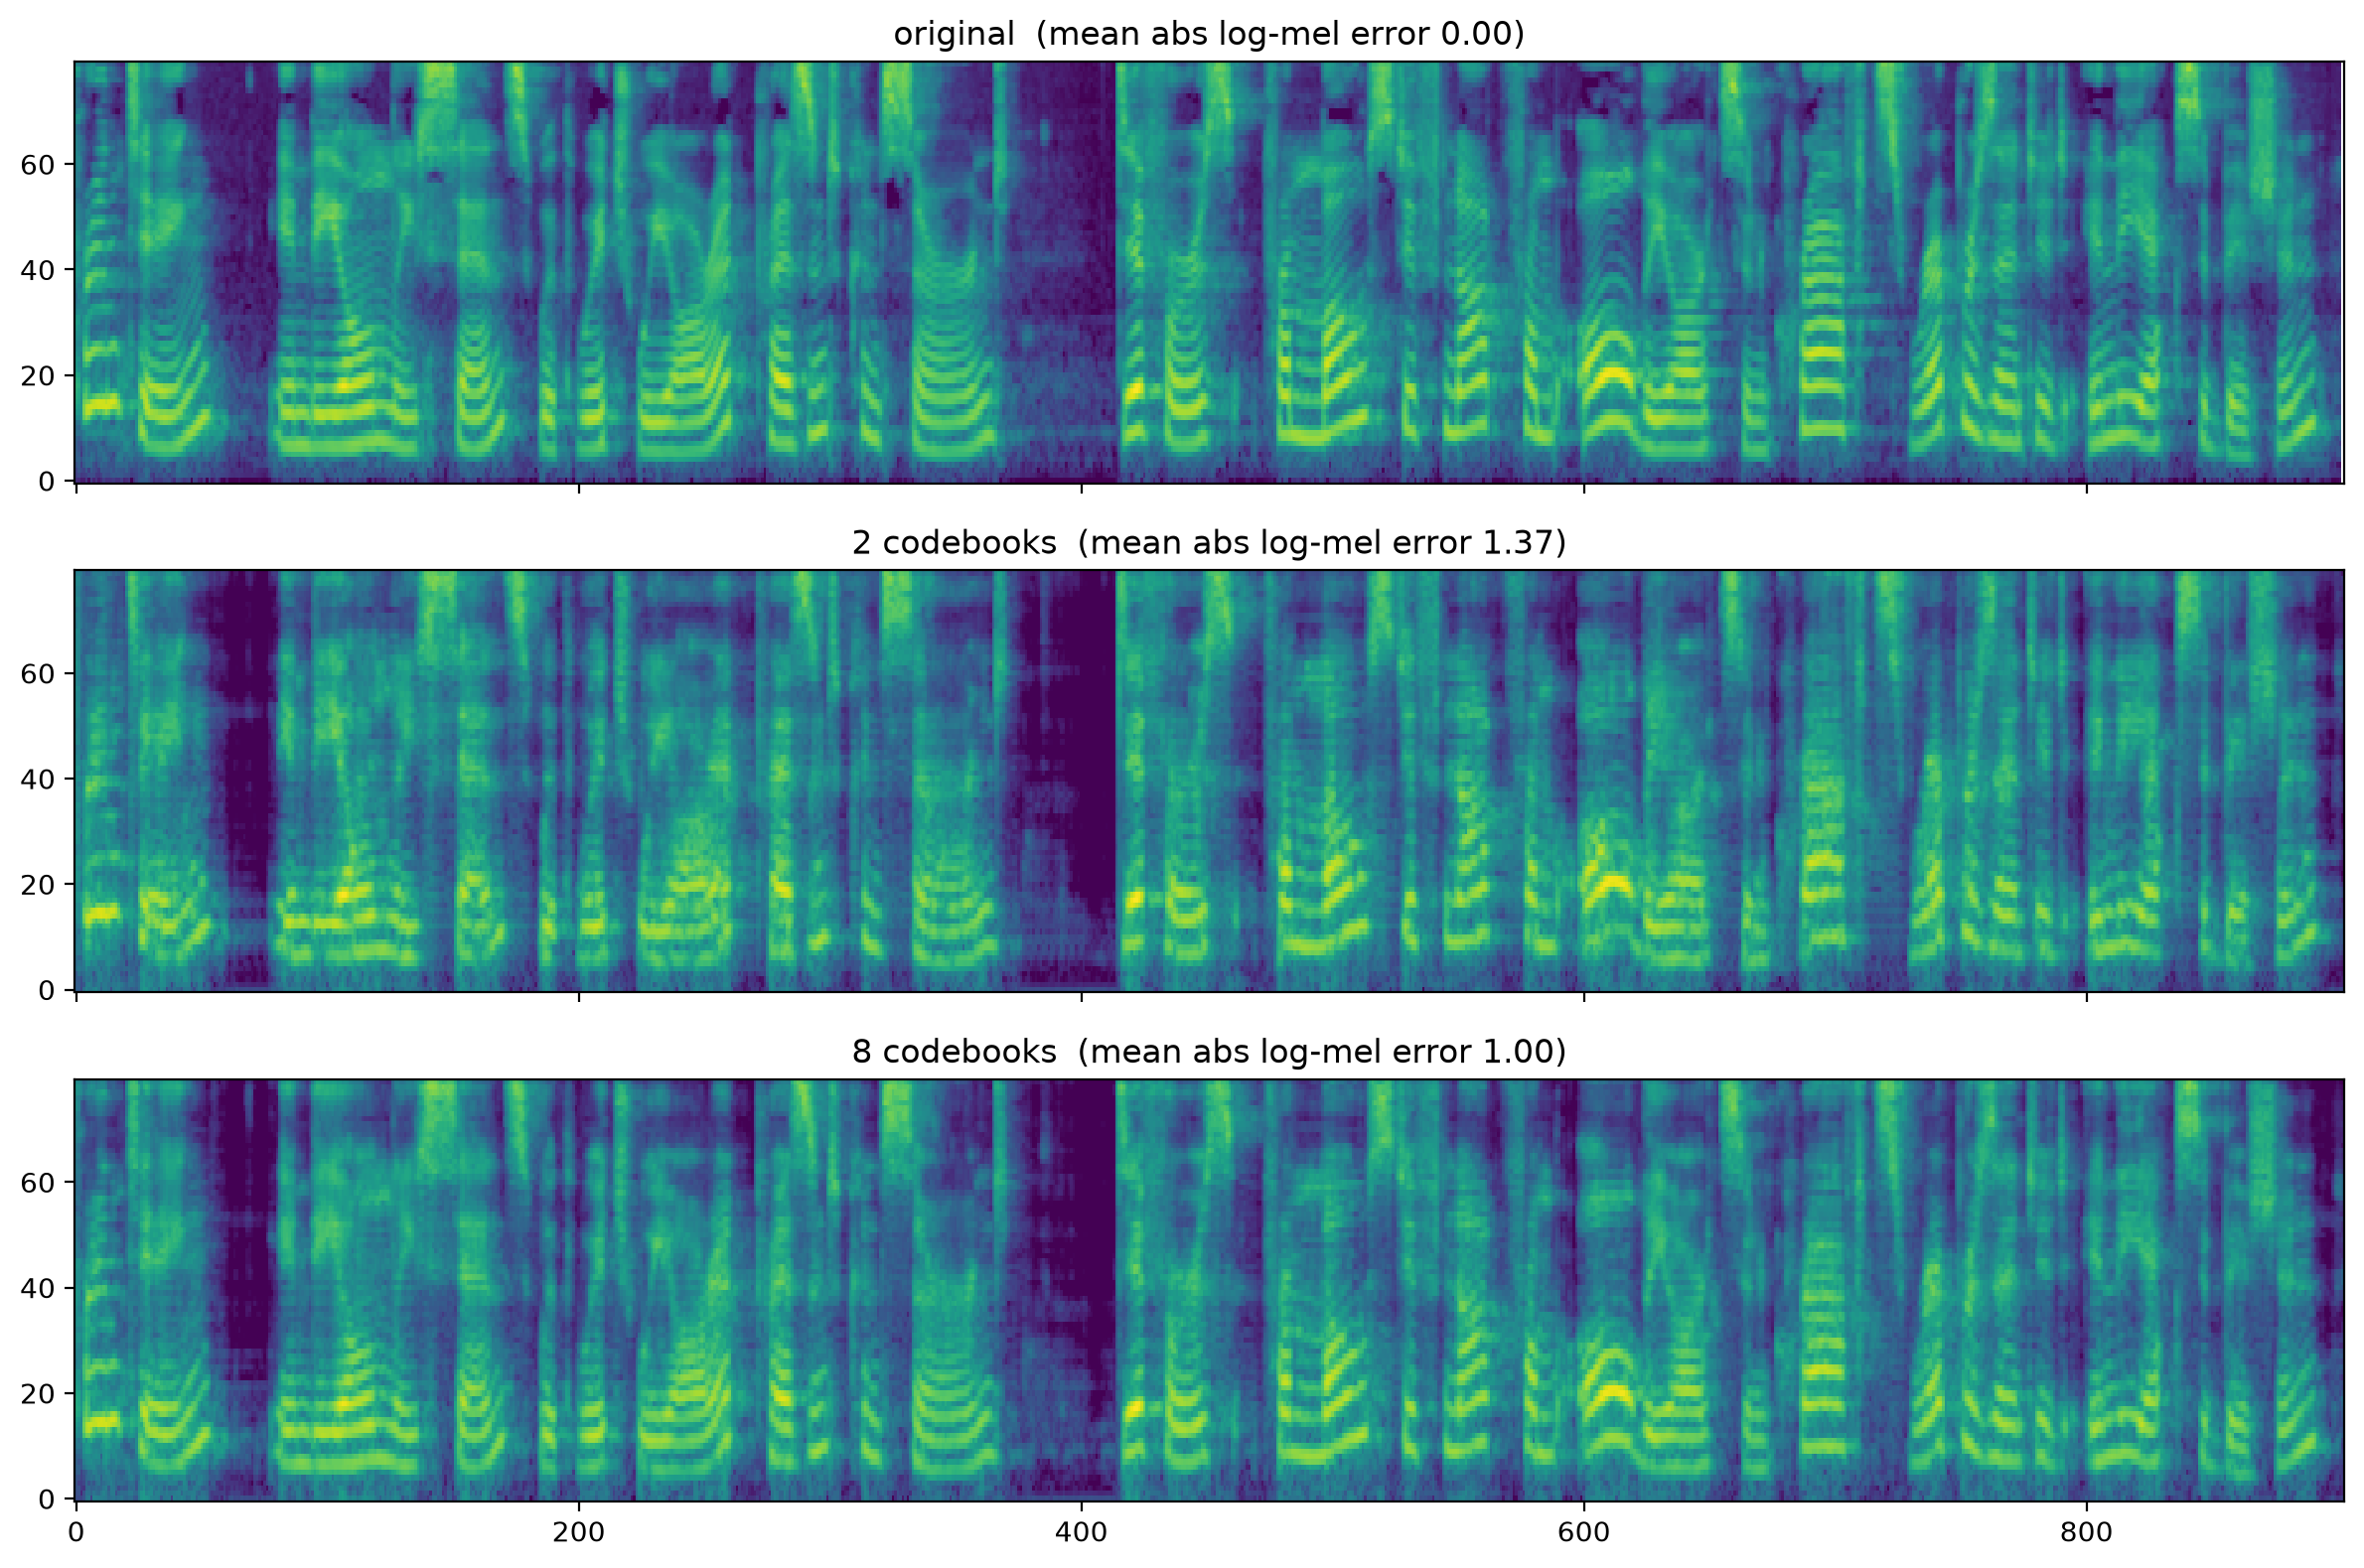

In [ ]:
def log_mel_of(signal, sr):
    fb = mel_filterbank(sr, n_fft, n_mels, f_min, f_max)
    spec = np.abs(np.fft.rfft(frame(signal, n_fft, hop) * window, axis=1))
    return np.log(np.maximum((spec**2) @ fb.T, 1e-5))


original_mel = log_mel_of(audio_24k, 24_000)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (label, m) in zip(
    axes,
    [
        ("original", original_mel),
        ("2 codebooks", log_mel_of(decode(codes[:2]), 24_000)),
        ("8 codebooks", log_mel_of(decode(codes[:8]), 24_000)),
    ],
):
    n = min(len(m), len(original_mel))
    error = np.abs(m[:n] - original_mel[:n]).mean()
    ax.imshow(m.T, origin="lower", aspect="auto", interpolation="nearest")
    ax.set_title(f"{label}  (mean abs log-mel error {error:.2f})")
plt.tight_layout()
plt.show()

With two codebooks the fine harmonic stripes blur together, which is the warble you heard. With eight they're back.

Notice we just used a mel spectrogram as a *measuring stick* for a codec. That's the other job mel spectrograms have:
even systems that don't predict them use them in the loss function, because "distance between log-mels" is a decent
proxy for "sounds different to a human". Piper's loss is 45 × that, plus GAN terms.

## Mimi: a codec designed for language models

EnCodec was built for compression. For TTS, 600 tokens per second (8 codebooks × 75 Hz) is a lot of tokens for a
transformer to generate: a ten second sentence is 6,000 tokens. Kyutai's **Mimi** codec (2024) was designed to fix
this, and it's what Pocket TTS predicts.

Two changes. First, a much lower frame rate: 12.5 frames per second, one every 80 ms, with a bigger codebook of 2,048.
Second, the first codebook isn't trained to reconstruct audio at all. It's trained to match the output of a speech
*understanding* model (WavLM), so it captures "what's being said" and leaves "how it sounds" to the other codebooks.
That split makes the token sequence much easier for a language model to predict.

In [ ]:
from transformers import MimiModel

mimi = MimiModel.from_pretrained("kyutai/mimi").eval()
print(
    f"{sum(p.numel() for p in mimi.parameters()) / 1e6:.0f}M parameters, "
    f"{mimi.config.frame_rate} Hz, codebook size {mimi.config.codebook_size}"
)

with torch.no_grad():
    mimi_codes = mimi.encode(x, num_quantizers=8).audio_codes  # 8 codebooks, as Pocket TTS uses
    mimi_out = mimi.decode(mimi_codes)[0][0, 0].numpy()

print(
    mimi_codes.shape,
    f"-> {mimi_codes.shape[-1] / (len(audio_24k) / 24_000):.1f} frames/s, "
    f"{mimi_codes.shape[1] * mimi.config.frame_rate:.0f} tokens/s",
)
Audio(mimi_out, rate=24_000)

79M parameters, 12.5 Hz, codebook size 2048
torch.Size([1, 8, 121]) -> 12.5 frames/s, 100 tokens/s


Loading weights: 100%|##########| 350/350 [00:00<00:00, 6371.72it/s]


Six times fewer tokens than EnCodec at 8 codebooks, and it sounds nearly as good. (If you measure it with our log-mel
error it scores a little worse than EnCodec-8, and about the same as EnCodec-2. That's the price of spending the first
codebook on meaning rather than sound. Whether your ears agree with the metric is a question worth sitting with, because
it's the central difficulty of evaluating TTS.) That's the difference a codec designed for generation makes, and it's why a 100M parameter model like Pocket TTS can be autoregressive and still run in real time
on a CPU.

One thing to keep in mind: the codec is itself a trained model, and we just used two off the shelf. Training your own is
a project on the scale of training the TTS model, so nearly everyone borrows one.

## The version the models use

The models in later notebooks need the mel spectrogram inside their training loops, on the GPU, differentiable. `torch.stft` does the framing,
windowing and FFT from last time in one call. Two details differ from the numpy version above:

1. **Padding.** We reflect-pad the signal by `(n_fft - hop) / 2` on each side before framing, so that we get exactly
   `samples / hop` frames. Then every mel frame lines up with exactly 256 samples, which is what the upsampling in the
   generator assumes.
2. **Conventions.** We use magnitude rather than power, and librosa's default mel filters (the "Slaney" variant, with
   area normalisation) rather than the HTK formula we derived. Why? Because this is what the HiFi-GAN reference
   implementation does, so it's what pretrained HiFi-GAN vocoders expect. Neither choice is better.
   Consistency is what matters.

In [ ]:
#| export
from functools import cache

import librosa
import numpy as np
import torch
import torch.nn.functional as F

In [ ]:
#| export
SR, N_FFT, HOP, N_MELS, F_MAX = 22050, 1024, 256, 80, 8000

In [ ]:
#| export
@cache
def mel_basis(device="cpu"):
    "(N_MELS, N_FFT // 2 + 1) mel filterbank. librosa's default Slaney variant, which HiFi-GAN uses."
    return torch.tensor(librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmin=0, fmax=F_MAX), device=device)


@cache
def hann(device="cpu"):
    return torch.hann_window(N_FFT, device=device)


def log_mel(y):
    "(batch, samples) waveform -> (batch, N_MELS, samples // HOP) log mel magnitude spectrogram."
    pad = (N_FFT - HOP) // 2
    y = F.pad(y, (pad, pad), mode="reflect")
    spec = torch.stft(y, N_FFT, HOP, N_FFT, hann(y.device), center=False, return_complex=True).abs()
    return torch.log(torch.clamp(mel_basis(y.device) @ spec, min=1e-5))

Exactly `samples / HOP` frames, and the same numbers librosa gets with the same conventions:

In [ ]:
pad = (N_FFT - HOP) // 2
ref = librosa.feature.melspectrogram(
    y=np.pad(audio, pad, mode="reflect"), sr=SR, n_fft=N_FFT, hop_length=HOP, center=False, power=1, n_mels=N_MELS, fmax=F_MAX
)
m = log_mel(torch.tensor(audio)[None])[0].numpy()
print(m.shape, len(audio) // HOP, np.allclose(m, np.log(np.maximum(ref, 1e-5)), atol=1e-3))

(80, 831) 831 True


And Griffin-Lim, for a vocoder that needs no training:

In [ ]:
#| export
def griffin_lim(mel, n_iter=32):
    "(N_MELS, frames) numpy log mel -> waveform, guessing the phase iteratively."
    linear = np.maximum(np.linalg.pinv(mel_basis().numpy()) @ np.exp(mel) ** 2, 0)
    return librosa.griffinlim(np.sqrt(linear), n_iter=n_iter, hop_length=HOP, win_length=N_FFT)

## Summary

Three ways to write down our 9.7 second clip:

| Representation | Shape | Per second | Type | Invertible? | Predicted by |
|---|---|---|---|---|---|
| Waveform | 212,893 | 22,050 | float | is the audio | VITS / Piper (directly) |
| Log mel spectrogram | 828 × 80 | 86 frames | float | lossy, needs a vocoder | Tacotron, FastSpeech, Matcha, Kokoro, F5 |
| EnCodec tokens (8 codebooks) | 725 × 8 | 600 tokens | int in [0, 1024) | via the codec decoder | VALL-E, Orpheus (similar codec) |
| Mimi tokens (8 codebooks) | 121 × 8 | 100 tokens | int in [0, 2048) | via the codec decoder | Pocket TTS, Kyutai TTS |

The mel spectrogram is what we'll reach for first: it's simple, we understand every line of it, and it gives us a
loss function for free. Tokens are what we'll reach for when we want to treat speech generation as a language modelling
problem.

## Things to try

- Remove the Hann window (set `window = np.ones(n_fft)`) and look at the spectrogram. Where does the smearing show up?
- Change `hop` to 512 and 128. What happens to the number of frames, and to the picture?
- Set `n_mels` to 20 and to 200. Run Griffin-Lim on each. When does it stop sounding like speech?
- Decode EnCodec with just *one* codebook. Then decode with codebooks 2–8 but not codebook 1 (set that row to zero).
  Which matters more?
- Take Mimi's first codebook only and decode. You should hear the "what" without the "how".